[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/01_why_attention.ipynb)

# 01 · Why Attention?

*Attention, Explained · Hamza Hentabli, Ph.D. · ~30 min*

Every modern language model — BERT, GPT, the Transformer itself — is built around one operation: **attention**. Before learning *how* it works, we need to see *why* it was invented. In this notebook we reproduce, on a tiny toy problem, the exact failure that motivated attention in 2015, and watch attention fix it.

**Learning objectives.** By the end of this notebook you will be able to:

- explain the **fixed-length bottleneck** of encoder–decoder RNNs
- describe attention as **looking back** at all input positions with learned weights
- train two tiny seq2seq models and **measure** the effect of attention on longer sequences
- read a learned **attention matrix**

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. A translation puzzle

Translate *"the black cat sat on the mat"* into French: **"le chat noir s'est assis sur le tapis"**.

Notice two things:

1. **Word order changes.** English says *black cat*; French says *chat noir* (cat black). To produce *noir* the translator must look back at *black*, which came **before** *cat*.
2. **Each output word depends mostly on one or two input words.** *tapis* depends on *mat*; *assis* depends on *sat*.

A human translator keeps the whole source sentence on the page and glances back at the relevant part while writing each word. That glance is exactly what **attention** formalises. The figure below is a hand-made *alignment* (it is our own annotation, not a model output) of which source word each French word mostly relies on.

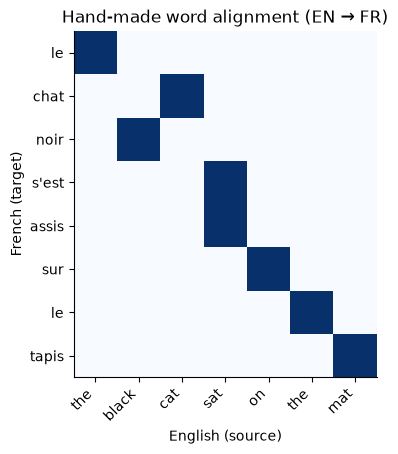

In [2]:
src = ["the", "black", "cat", "sat", "on", "the", "mat"]
tgt = ["le", "chat", "noir", "s'est", "assis", "sur", "le", "tapis"]
# hand annotation: target word -> source positions it relies on
align = {0: [0], 1: [2], 2: [1], 3: [3], 4: [3], 5: [4], 6: [5], 7: [6]}
A = np.zeros((len(tgt), len(src)))
for t, ss in align.items():
    A[t, ss] = 1.0 / len(ss)

fig, ax = plt.subplots(figsize=(6, 4.5))
au.plot_attention(A, tgt, src, ax=ax, annotate=False, title="Hand-made word alignment (EN → FR)")
ax.set_xlabel("English (source)"); ax.set_ylabel("French (target)")
plt.show()

Notice how the `chat`/`noir` rows *cross*: the order flips. A model that reads the source left-to-right and then writes the target has to remember **where** each piece of information was.

## 2. The encoder–decoder bottleneck

Before 2014–2015, neural machine translation used a **sequence-to-sequence (seq2seq)** model built from two recurrent networks (RNNs):

- the **encoder** reads the source one token at a time and updates a hidden state $h_t$;
- the **decoder** starts from the **last** encoder state $h_T$ and generates the target one token at a time.

Everything the decoder knows about the source must squeeze through that single fixed-length vector $h_T$. A 5-word sentence and a 50-word paragraph get the *same* number of numbers. That is the **bottleneck**.

**Attention** (Bahdanau, Cho & Bengio, 2015) removes the bottleneck: at every output step the decoder computes a weighted average of **all** encoder states, with weights that say *how relevant each source position is right now*. Nothing has to be crammed into one vector.

Rather than take that on faith, let's **measure** it.

## 3. Experiment: reverse a sequence, with and without attention

Our toy "translation" task: the source is a random sequence of digits, the target is the **same digits reversed** (`3 8 1 5 → 5 1 8 3`). It is the purest form of "word order changes": the first output digit depends on the **last** input digit, and so on.

We train two GRU seq2seq models that are identical except for one thing:

| model | what the decoder sees at each step |
|-------|-----------------------------------|
| **no attention** | only its own state, initialised from the final encoder state $h_T$ |
| **attention** | its own state **plus** a context vector = attention-weighted average of all encoder states |

Both are trained on lengths 3–20 for the same number of steps, then evaluated on lengths 4, 8, 12, 16, 20.

In [3]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
VOCAB, SOS = 12, 1          # tokens 2..11 are the ten "digits", 1 = start-of-sequence
HID, EMB = 64, 32

def make_batch(batch_size, length):
    x = torch.randint(2, VOCAB, (batch_size, length))
    return x, x.flip(1)               # target = reversed source

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, EMB)
        self.rnn = nn.GRU(EMB, HID, batch_first=True)
    def forward(self, x):
        states, h_last = self.rnn(self.emb(x))
        return states, h_last          # states: (B, T, HID) = one vector per source token

class Decoder(nn.Module):
    def __init__(self, use_attention):
        super().__init__()
        self.use_attention = use_attention
        self.emb = nn.Embedding(VOCAB, EMB)
        extra = HID if use_attention else 0
        self.rnn = nn.GRU(EMB + extra, HID, batch_first=True)
        self.out = nn.Linear(HID + extra, VOCAB)

    def step(self, token, h, enc_states):
        e = self.emb(token)                                   # (B, 1, EMB)
        if not self.use_attention:
            o, h = self.rnn(e, h)
            return self.out(o), h, None
        # --- attention: score every encoder state against the current decoder state ---
        scores = (enc_states @ h[-1].unsqueeze(2)).squeeze(2) / HID ** 0.5   # (B, T)
        weights = scores.softmax(dim=1)                                       # sums to 1 over T
        context = (weights.unsqueeze(2) * enc_states).sum(1, keepdim=True)  # (B, 1, HID)
        o, h = self.rnn(torch.cat([e, context], 2), h)
        return self.out(torch.cat([o, context], 2)), h, weights

def decode(dec, enc_states, h, y=None, length=None):
    """Teacher forcing if y is given, otherwise greedy decoding."""
    B = enc_states.shape[0]
    length = y.shape[1] if y is not None else length
    token = torch.full((B, 1), SOS)
    logits, attn = [], []
    for t in range(length):
        lg, h, w = dec.step(token, h, enc_states)
        logits.append(lg); attn.append(w)
        token = y[:, t:t + 1] if y is not None else lg.argmax(-1)
    return torch.cat(logits, 1), attn

In [4]:
def train(use_attention, steps=2500, max_len=20, seed=0):
    au.set_seed(seed)
    enc, dec = Encoder(), Decoder(use_attention)
    opt = torch.optim.Adam([*enc.parameters(), *dec.parameters()], lr=3e-3)
    losses = []
    for s in range(steps):
        L = np.random.randint(3, max_len + 1)
        x, y = make_batch(64, L)
        states, h = enc(x)
        logits, _ = decode(dec, states, h, y=y)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), y.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return enc, dec, losses

@torch.no_grad()
def accuracy(enc, dec, length, n=500):
    torch.manual_seed(123)
    x, y = make_batch(n, length)
    states, h = enc(x)
    logits, _ = decode(dec, states, h, length=length)
    return (logits.argmax(-1) == y).float().mean().item()

results, models = {}, {}
for use_attention in (False, True):
    t0 = time.time()
    enc, dec, losses = train(use_attention)
    name = "attention" if use_attention else "no attention"
    models[name] = (enc, dec)
    results[name] = {L: accuracy(enc, dec, L) for L in (4, 8, 12, 16, 20)}
    print(f"{name:13s} final train loss {np.mean(losses[-100:]):.3f}  ({time.time() - t0:.0f} s)")

print()
print("length  " + "  ".join(f"{L:>6d}" for L in (4, 8, 12, 16, 20)))
for name, accs in results.items():
    print(f"{name:13s}" + "  ".join(f"{a:6.3f}" for a in accs.values()))

no attention  final train loss 0.356  (17 s)


attention     final train loss 0.098  (24 s)

length       4       8      12      16      20
no attention  1.000   0.928   0.700   0.475   0.376
attention     0.999   0.981   0.918   0.832   0.707


The numbers above are per-digit accuracy from greedy decoding on 500 fresh sequences per length (chance is 0.10). Let's plot them.

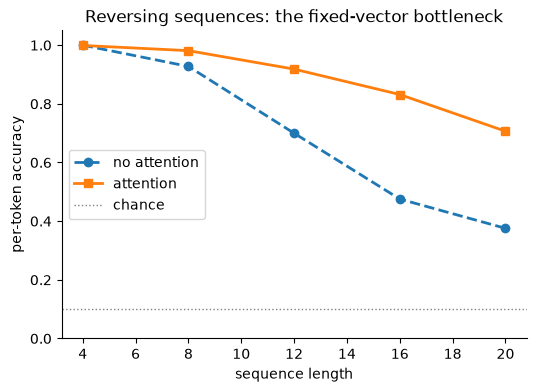

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, style in (("no attention", "o--"), ("attention", "s-")):
    Ls = list(results[name]); ax.plot(Ls, [results[name][L] for L in Ls], style, lw=2, label=name)
ax.axhline(0.1, color="grey", lw=1, ls=":", label="chance")
ax.set_xlabel("sequence length"); ax.set_ylabel("per-token accuracy")
ax.set_title("Reversing sequences: the fixed-vector bottleneck")
ax.set_ylim(0, 1.05); ax.legend()
au.save_fig(fig, "01_bottleneck_accuracy.png")
plt.show()

**What you should see:** on short sequences both models are nearly perfect. As sequences get longer, the model **without** attention degrades much faster, because more and more information has to fit through the same 64 numbers. The attention model degrades far more gracefully: it never has to memorise the whole input, it just *looks it up*.

(Exact numbers vary a little between machines and PyTorch versions; the gap is the point.)

## 4. Look at what the attention model learned

The attention model produced, at every output step, a probability distribution over the input positions. For reversal, output step $t$ should look at input position $T-1-t$, so the attention matrix should be an **anti-diagonal**. Nobody told the model this; it had to discover it from the loss.

input   : 5 2 1 6 3 7 7 9 8 1
output  : 1 8 9 7 7 3 6 1 2 5
expected: 1 8 9 7 7 3 6 1 2 5


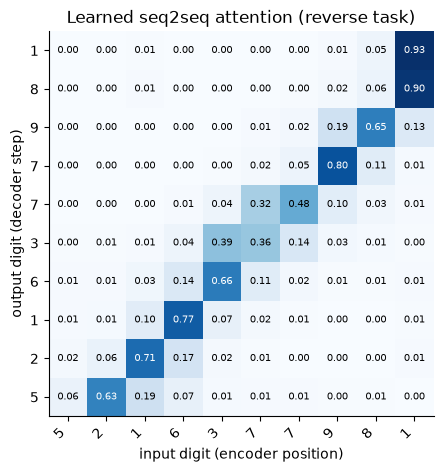

In [6]:
enc, dec = models["attention"]
torch.manual_seed(7)
x, y = make_batch(1, 10)
with torch.no_grad():
    states, h = enc(x)
    logits, attn = decode(dec, states, h, length=10)
W = torch.cat(attn, 0).numpy()          # (output steps, input positions)
src_lbl = [str(int(t) - 2) for t in x[0]]
out_lbl = [str(int(t) - 2) for t in logits.argmax(-1)[0]]
print("input   :", " ".join(src_lbl))
print("output  :", " ".join(out_lbl))
print("expected:", " ".join(str(int(t) - 2) for t in y[0]))

fig, ax = plt.subplots(figsize=(6, 5))
au.plot_attention(W, out_lbl, src_lbl, ax=ax, title="Learned seq2seq attention (reverse task)")
ax.set_xlabel("input digit (encoder position)"); ax.set_ylabel("output digit (decoder step)")
au.save_fig(fig, "01_seq2seq_attention.png")
plt.show()

The bright cells run from the **top-right to the bottom-left**: the first output digit attends to the last input digit, and so on. This is the same idea as the hand-made translation alignment in section 1, but this time it was **learned**.

## Key takeaways

- A plain encoder–decoder must compress the whole input into **one fixed-length vector**, and that bottleneck hurts more as inputs grow.
- **Attention** lets every output step take a **weighted average over all input states**, with weights computed on the fly.
- The weights are interpretable: they show *where the model is looking*.

The rest of the course opens up that weighted average: what the vectors are (Notebook 02), how the weights are computed (03–05), and how attention alone, without any RNN, became the Transformer (06–12).

### ✏️ Exercise 1

Print the attention model's accuracy on length-20 sequences divided by the no-attention model's accuracy. How many times better is it?

<details>
<summary><b>Show solution</b></summary>

```python
print(results["attention"][20] / results["no attention"][20])
```



</details>

### ✏️ Exercise 2

For the 10-digit example above, use `W.argmax(axis=1)` to find which input position each output step attends to most. Is it `9, 8, 7, …, 0`?

<details>
<summary><b>Show solution</b></summary>

```python
print(W.argmax(axis=1))   # for reversal the ideal answer is [9 8 7 6 5 4 3 2 1 0]
```



</details>

### ✏️ Exercise 3

Evaluate both trained models on length **25** sequences — longer than anything seen in training. Which one generalises better?

<details>
<summary><b>Show solution</b></summary>

```python
for name, (e, d) in models.items():
    print(name, round(accuracy(e, d, 25), 3))
```

Both get worse outside the training range, but the attention model usually stays well ahead.

</details>